# Rossmann Store Sales Forecasting

## 1. Project Overview

Rossmann is a retail drugstore chain operating multiple stores across different locations. Store sales are influenced by several factors, including promotions, holidays, competition, store characteristics, and seasonal patterns.

The objective of this project is to develop machine learning models to predict daily sales and customer visits for individual Rossmann stores. Accurate forecasting can help businesses understand future demand, improve resource allocation, and support better operational and promotional planning.

This project uses historical store-level data to perform data preprocessing, exploratory data analysis, feature engineering, model development, and evaluation. Multiple regression algorithms are compared to identify the best-performing models for Sales and Customers prediction.

## 2. Problem Statement

The objective is to predict daily sales revenue and the number of customers for Rossmann stores using historical sales data, store information, promotional activities, holidays, competition-related variables, and date-based features.

The developed models should provide reliable predictions for future dates and help support business decisions related to inventory planning, staffing, and sales management.

## 3. Project Objectives

- Understand historical sales and customer patterns through exploratory data analysis.
- Identify the impact of promotions, holidays, competition, and calendar-related factors.
- Perform data cleaning, preprocessing, and feature engineering.
- Develop separate machine learning regression models for Sales and Customers prediction.
- Compare multiple algorithms using appropriate evaluation metrics.
- Select and serialize the best-performing models.
- Generate predictions for the test dataset.
- Combine Sales and Customers predictions into a single store-level output for further analysis and deployment.

## 4. Dataset Description

The project uses three primary datasets:

- **Train Dataset:** Historical store-level records containing Sales, Customers, and other relevant features.
- **Test Dataset:** Store-level records for future dates where Sales and Customers need to be predicted.
- **Store Dataset:** Additional store-related information, including store type, assortment, competition, and promotional details.

The training data covers January 2013 to July 2015, while the test data covers August to September 2015.

## Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import os

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    RandomizedSearchCV
)

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

## Load Datasets

In [3]:
BASE_DIR = os.path.abspath("..")

OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")
MODEL_DIR = os.path.join(BASE_DIR, "models")
PROCESSED_DIR = os.path.join(BASE_DIR, "processed")
PLOT_DIR = os.path.join(BASE_DIR, "outputs", "plots")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

In [24]:
train_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "train_merged.csv"),
    parse_dates=["Date"],
    dtype={"StateHoliday": "string"}
)

test_df = pd.read_csv(
    os.path.join(OUTPUT_DIR, "test_merged.csv"),
    parse_dates=["Date"],
    dtype={"StateHoliday": "string"}
)

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

display(train_df.head())
display(test_df.head())

Training Shape: (1017209, 20)
Testing Shape: (41088, 19)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionOpenDateMissing,CompetitionDistance_Original
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,0.0,0.0,NaN,0,1270.0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",0,570.0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0,14130.0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,0.0,0.0,NaN,0,620.0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,16107.5,4.0,2015.0,0,0.0,0.0,NaN,0,29910.0


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionOpenDateMissing,CompetitionDistance_Original
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,9.0,2008.0,0,0.0,0.0,NaN,0,1270.0
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0,14130.0
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,16107.5,4.0,2013.0,0,0.0,0.0,NaN,0,24000.0
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,10.0,2014.0,0,0.0,0.0,NaN,0,7520.0
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,8.0,2000.0,0,0.0,0.0,NaN,0,2030.0


## Data Understanding and Preprocessing

In [25]:
print("Training Data Types:")
display(train_df.dtypes)

print("Testing Data Types:")
display(test_df.dtypes)

Training Data Types:


Store                                    int64
DayOfWeek                                int64
Date                            datetime64[ns]
Sales                                    int64
Customers                                int64
Open                                     int64
Promo                                    int64
StateHoliday                    string[python]
SchoolHoliday                            int64
StoreType                               object
Assortment                              object
CompetitionDistance                    float64
CompetitionOpenSinceMonth              float64
CompetitionOpenSinceYear               float64
Promo2                                   int64
Promo2SinceWeek                        float64
Promo2SinceYear                        float64
PromoInterval                           object
CompetitionOpenDateMissing               int64
CompetitionDistance_Original           float64
dtype: object

Testing Data Types:


Id                                       int64
Store                                    int64
DayOfWeek                                int64
Date                            datetime64[ns]
Open                                   float64
Promo                                    int64
StateHoliday                    string[python]
SchoolHoliday                            int64
StoreType                               object
Assortment                              object
CompetitionDistance                    float64
CompetitionOpenSinceMonth              float64
CompetitionOpenSinceYear               float64
Promo2                                   int64
Promo2SinceWeek                        float64
Promo2SinceYear                        float64
PromoInterval                           object
CompetitionOpenDateMissing               int64
CompetitionDistance_Original           float64
dtype: object

In [26]:
print("Sales Statistics:")
display(train_df["Sales"].describe())

Sales Statistics:


count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

In [27]:
print("Missing Values in Training:")
display(train_df.isnull().sum()[train_df.isnull().sum() > 0])

print("Missing Values in Testing:")
display(test_df.isnull().sum()[test_df.isnull().sum() > 0])

Missing Values in Training:


PromoInterval    508031
dtype: int64

Missing Values in Testing:


PromoInterval    17232
dtype: int64

In [28]:
for df in [train_df, test_df]:

    df["PromoInterval"] = (
        df["PromoInterval"].fillna("No Promo2")
    )

In [29]:
print(test_df["Open"].isnull().sum())

0


## Feature Engineering

In [30]:
def create_date_features(df):

    df = df.copy()

    # Basic date features
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Day"] = df["Date"].dt.day

    # Weekday
    df["DayOfWeek"] = df["Date"].dt.dayofweek

    # Weekend indicator
    df["IsWeekend"] = (
        df["DayOfWeek"].isin([5, 6]).astype(int)
    )

    # Week of year
    df["WeekOfYear"] = (
        df["Date"].dt.isocalendar().week.astype(int)
    )

    # Quarter
    df["Quarter"] = df["Date"].dt.quarter

    # Beginning, middle and end of month
    df["MonthPeriod"] = np.select(
        [
            df["Day"] <= 10,
            df["Day"].between(11, 20)
        ],
        [
            "Beginning",
            "Middle"
        ],
        default="End"
    )

    # Month start and end indicators
    df["IsMonthStart"] = (
        df["Date"].dt.is_month_start.astype(int)
    )

    df["IsMonthEnd"] = (
        df["Date"].dt.is_month_end.astype(int)
    )

    # Year start and year end indicators
    df["IsYearStart"] = (
        df["Date"].dt.is_year_start.astype(int)
    )

    df["IsYearEnd"] = (
        df["Date"].dt.is_year_end.astype(int)
    )

    # Weekend and month interaction
    df["IsWeekend"] = df["IsWeekend"].astype(int)

    return df

In [31]:
train_df = create_date_features(train_df)
test_df = create_date_features(test_df)

display(train_df.head())

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,Month,Day,IsWeekend,WeekOfYear,Quarter,MonthPeriod,IsMonthStart,IsMonthEnd,IsYearStart,IsYearEnd
0,1,4,2015-07-31,5263,555,1,1,0,1,c,...,7,31,0,31,3,End,0,1,0,0
1,2,4,2015-07-31,6064,625,1,1,0,1,a,...,7,31,0,31,3,End,0,1,0,0
2,3,4,2015-07-31,8314,821,1,1,0,1,a,...,7,31,0,31,3,End,0,1,0,0
3,4,4,2015-07-31,13995,1498,1,1,0,1,c,...,7,31,0,31,3,End,0,1,0,0
4,5,4,2015-07-31,4822,559,1,1,0,1,a,...,7,31,0,31,3,End,0,1,0,0


In [32]:
calendar_df = pd.concat(
    [
        train_df[["Date", "StateHoliday"]],
        test_df[["Date", "StateHoliday"]]
    ],
    ignore_index=True
)

# Convert dates to datetime
calendar_df["Date"] = pd.to_datetime(calendar_df["Date"])

# Extract dates marked as state holidays
holiday_dates = np.sort(
    calendar_df.loc[
        calendar_df["StateHoliday"].notna()
        & (calendar_df["StateHoliday"].astype(str) != "0"),
        "Date"
    ].drop_duplicates().values
)

holiday_dates = holiday_dates.astype("datetime64[ns]")

print("First holiday:", holiday_dates.min())
print("Last holiday:", holiday_dates.max())
print("Total holiday dates:", len(holiday_dates))

First holiday: 2013-01-01T00:00:00.000000000
Last holiday: 2015-08-15T00:00:00.000000000
Total holiday dates: 38


In [33]:
# Add the next nationwide German public holiday
additional_holidays = np.array(
    ["2015-10-03"],
    dtype="datetime64[ns]"
)

# Combine and remove duplicate dates
holiday_dates = np.sort(
    np.unique(
        np.concatenate([
            holiday_dates,
            additional_holidays
        ])
    )
)

In [34]:
def add_holiday_distance_features(df, holiday_dates):

    df = df.copy()

    # Ensure dates are in datetime format
    dates = pd.to_datetime(df["Date"]).values

    # Ensure holiday dates are sorted and unique
    holiday_dates = np.sort(
        np.unique(
            holiday_dates.astype("datetime64[ns]")
        )
    )

    # Find the next holiday
    next_idx = np.searchsorted(
        holiday_dates,
        dates,
        side="left"
    )

    days_to = np.full(len(df), np.nan)

    valid_next = next_idx < len(holiday_dates)

    days_to[valid_next] = (
        holiday_dates[next_idx[valid_next]] - dates[valid_next]
    ).astype("timedelta64[D]").astype(int)

    # Find the previous holiday
    previous_idx = np.searchsorted(
        holiday_dates,
        dates,
        side="right"
    ) - 1

    days_after = np.full(len(df), np.nan)

    valid_previous = previous_idx >= 0

    days_after[valid_previous] = (
        dates[valid_previous] -
        holiday_dates[previous_idx[valid_previous]]
    ).astype("timedelta64[D]").astype(int)

    # Add features
    df["Days_To_StateHoliday"] = days_to
    df["Days_After_StateHoliday"] = days_after

    return df

train_df = add_holiday_distance_features(
    train_df,
    holiday_dates
)

test_df = add_holiday_distance_features(
    test_df,
    holiday_dates
)

In [35]:
def add_competition_features(df):

    df = df.copy()

    df["CompetitionOpenSince"] = pd.to_datetime(
        dict(
            year=df["CompetitionOpenSinceYear"],
            month=df["CompetitionOpenSinceMonth"],
            day=1
        ),
        errors="coerce"
    )

    df["CompetitionOpenMonths"] = (
        (df["Date"].dt.year -
         df["CompetitionOpenSince"].dt.year) * 12
        +
        (df["Date"].dt.month -
         df["CompetitionOpenSince"].dt.month)
    )

    # Do not treat missing opening dates as zero months
    df.loc[
        df["CompetitionOpenSince"].isna(),
        "CompetitionOpenMonths"
    ] = np.nan

    df.drop(
        columns=["CompetitionOpenSince"],
        inplace=True
    )

    return df

train_df = add_competition_features(train_df)
test_df = add_competition_features(test_df)

In [36]:
def add_promo2_active(df):

    df = df.copy()

    iso = df["Date"].dt.isocalendar()

    current_year = iso.year.astype(int)
    current_week = iso.week.astype(int)

    started = (
        (current_year > df["Promo2SinceYear"]) |
        (
            (current_year == df["Promo2SinceYear"]) &
            (current_week >= df["Promo2SinceWeek"])
        )
    )

    active_month = df.apply(
        lambda row: (
            row["Date"].strftime("%b")
            in str(row["PromoInterval"]).split(",")
        ),
        axis=1
    )

    df["Promo2Active"] = (
        (df["Promo2"] == 1)
        & started
        & active_month
    ).astype(int)

    return df

train_df = add_promo2_active(train_df)
test_df = add_promo2_active(test_df)

In [37]:
new_features = [
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "IsWeekend",
    "WeekOfYear",
    "Quarter",
    "MonthPeriod",
    "IsMonthStart",
    "IsMonthEnd",
    "Days_To_StateHoliday",
    "Days_After_StateHoliday",
    "CompetitionOpenMonths",
    "Promo2Active"
]

display(train_df[new_features].head(10))

,Year,Month,Day,DayOfWeek,IsWeekend,WeekOfYear,Quarter,MonthPeriod,IsMonthStart,IsMonthEnd,Days_To_StateHoliday,Days_After_StateHoliday,CompetitionOpenMonths,Promo2Active
0,2015,7,31,4,0,31,3,End,0,1,15.0,57.0,82.0,0
1,2015,7,31,4,0,31,3,End,0,1,15.0,57.0,92.0,1
2,2015,7,31,4,0,31,3,End,0,1,15.0,57.0,103.0,1
3,2015,7,31,4,0,31,3,End,0,1,15.0,57.0,70.0,0
4,2015,7,31,4,0,31,3,End,0,1,15.0,57.0,3.0,0
5,2015,7,31,4,0,31,3,End,0,1,15.0,57.0,19.0,0
6,2015,7,31,4,0,31,3,End,0,1,15.0,57.0,27.0,0
7,2015,7,31,4,0,31,3,End,0,1,15.0,57.0,9.0,0
8,2015,7,31,4,0,31,3,End,0,1,15.0,57.0,179.0,0
9,2015,7,31,4,0,31,3,End,0,1,15.0,57.0,70.0,0


In [38]:
print("Training missing values:")
display(train_df.isnull().sum()[train_df.isnull().sum() > 0])

print("Testing missing values:")
display(test_df.isnull().sum()[test_df.isnull().sum() > 0])

Training missing values:


CompetitionOpenMonths    323348
dtype: int64

Testing missing values:


CompetitionOpenMonths    15216
dtype: int64

In [39]:
for df in [train_df, test_df]:
    df["CompetitionMonths_Missing"] = (
        df["CompetitionOpenMonths"].isna().astype(int)
    )

In [40]:
print("Sales missing values:", train_df["Sales"].isna().sum())
print("Customers missing values:", train_df["Customers"].isna().sum())

print("Test Sales column:", "Sales" in test_df.columns)
print("Test Customers column:", "Customers" in test_df.columns)

print(train_df[["Sales", "Customers"]].describe())

Sales missing values: 0
Customers missing values: 0
Test Sales column: False
Test Customers column: False
              Sales     Customers
count  1.017209e+06  1.017209e+06
mean   5.773819e+03  6.331459e+02
std    3.849926e+03  4.644117e+02
min    0.000000e+00  0.000000e+00
25%    3.727000e+03  4.050000e+02
50%    5.744000e+03  6.090000e+02
75%    7.856000e+03  8.370000e+02
max    4.155100e+04  7.388000e+03


## Build Machine learning Models

### Select Features and Target Variable

In [41]:
target = "Sales"

drop_columns = [
    "Sales",
    "Customers",
    "Id",
    "Date",
    "PromoInterval",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear",
    "Promo2SinceWeek",
    "Promo2SinceYear"
]

X = train_df.drop(
    columns=drop_columns,
    errors="ignore"
)

y = train_df[target].copy()

X_test = test_df.drop(
    columns=drop_columns,
    errors="ignore"
)

print("X Shape:", X.shape)
print("y Shape:", y.shape)
print("X_test Shape:", X_test.shape)

X Shape: (1017209, 28)
y Shape: (1017209,)
X_test Shape: (41088, 28)


Features we will exclude for training the model:
- Customers: unavailable in the test dataset.
- Id: identifier, not a useful predictive feature.
- Date: already converted into date features.
- Sales: target variable, to be predicted.
- PromoInterval: we have created Promo2Active from it.
- Original competition start year/month and Promo2 start year/week: their information is represented through engineered features.
+ We will retain Store, StoreType, Assortment, StateHoliday, and other useful variables.

### Time Based Validation Split

In [42]:
# Six weeks before the last training date
validation_start = (
    train_df["Date"].max() - pd.Timedelta(weeks=6)
)

train_mask = train_df["Date"] < validation_start
valid_mask = train_df["Date"] >= validation_start

X_train = X.loc[train_mask].copy()
X_valid = X.loc[valid_mask].copy()

y_train = y.loc[train_mask].copy()
y_valid = y.loc[valid_mask].copy()

print("Training records:", X_train.shape)
print("Validation records:", X_valid.shape)

print("Training date range:")
print(train_df.loc[train_mask, "Date"].min(),
      "to",
      train_df.loc[train_mask, "Date"].max())

print("Validation date range:")
print(train_df.loc[valid_mask, "Date"].min(),
      "to",
      train_df.loc[valid_mask, "Date"].max())

Training records: (969264, 28)
Validation records: (47945, 28)
Training date range:
2013-01-01 00:00:00 to 2015-06-18 00:00:00
Validation date range:
2015-06-19 00:00:00 to 2015-07-31 00:00:00


#### Insight 
Since our training dataset covers January 2013 to July 2015, while the test dataset covers August to September 2015. We should simulate forecasting future dates by training on earlier dates and validating on the latest six weeks of the training period. We can't use a random train-test split here because it can mix future and past records.

### Numerical and Categorical Columns

In [43]:
categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "int32", "float64", "float32", "bool"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['StateHoliday', 'StoreType', 'Assortment', 'MonthPeriod']

Numerical Features:
['Store', 'DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'CompetitionDistance', 'Promo2', 'CompetitionOpenDateMissing', 'CompetitionDistance_Original', 'Year', 'Month', 'Day', 'IsWeekend', 'WeekOfYear', 'Quarter', 'IsMonthStart', 'IsMonthEnd', 'IsYearStart', 'IsYearEnd', 'Days_To_StateHoliday', 'Days_After_StateHoliday', 'CompetitionOpenMonths', 'Promo2Active', 'CompetitionMonths_Missing']


### Preprocessing Pipeline

In [44]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

#### Insight
Build  Scikit-learn pipelines, as it applies the same preprocessing to training, validation and test data. It prevents the imputer and scaler from learning information from the validation or test set and makes the complete model easier to save and reuse. It is used for:
+ Median imputation for numerical missing values in competitionOpenMonths column.
+ StandardScaler for numerical features.
+ Most-frequent imputation for categorical features.
+ OneHotEncoder for categorical features.

### Train Multiple Regression Models
We will compare four models:
1. Linear Regression – baseline model.
2. Decision Tree Regressor – simple tree-based model.
3. Random Forest Regressor – recommended starting point in the project.
4. Gradient Boosting Regressor – boosting-based model.

In [45]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=20,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        max_depth=15,
        min_samples_leaf=10,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=50,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=10,
        random_state=42
    )
}

### Models Evaluation

In [46]:
def calculate_rmspe(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mask = y_true != 0

    return np.sqrt(
        np.mean(
            ((y_true[mask] - y_pred[mask]) /
             y_true[mask]) ** 2
        )
    ) * 100

def evaluate_model(model, X_valid, y_valid):

    predictions = model.predict(X_valid)

    predictions = np.maximum(predictions, 0)

    mae = mean_absolute_error(
        y_valid, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_valid, predictions)
    )

    r2 = r2_score(
        y_valid, predictions
    )

    rmspe = calculate_rmspe(
        y_valid, predictions
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "RMSPE": rmspe
    }

In [47]:
trained_models = {}
results = []

for name, model in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    metrics = evaluate_model(
        pipeline,
        X_valid,
        y_valid
    )

    metrics["Model"] = name

    results.append(metrics)

    print(f"{name} completed!")


Training Linear Regression...
Linear Regression completed!

Training Decision Tree...
Decision Tree completed!

Training Random Forest...
Random Forest completed!

Training Gradient Boosting...
Gradient Boosting completed!


In [48]:
results_df = pd.DataFrame(results)

results_df = results_df[
    ["Model", "MAE", "RMSE", "R2", "RMSPE"]
].sort_values("RMSPE")

display(results_df.round(3))

,Model,MAE,RMSE,R2,RMSPE
1,Decision Tree,917.938,1455.958,0.846,22.699
2,Random Forest,1387.856,2062.699,0.691,36.163
3,Gradient Boosting,1749.440,2547.381,0.529,46.744
0,Linear Regression,1674.223,2430.041,0.571,47.527


#### Observations
1. Decision Tree performs best: It achieves the lowest MAE (917.938) and RMSE (1455.95), along with the highest R² (0.846). This indicates that it explains approximately 84.6% of the variation in sales on your validation dataset.

2. Random Forest performs unexpectedly worse: Despite being an ensemble of decision trees, it achieves an R² of only 0.691. Its MAE and RMSE are also higher than those of the Decision Tree. This suggests that your current Random Forest configuration may not be capturing the patterns as effectively.

3. Gradient Boosting has the weakest performance: It produces an R² of 0.529 and an RMSE of 2547.38, indicating relatively poor predictive performance with the current hyperparameters.

4. Linear Regression struggles with the data: Its R² of 0.571 suggests that a simple linear relationship between the input features and sales is insufficient to capture the underlying patterns.

6. RMSPE supports the Decision Tree result: Decision Tree has the lowest RMSPE of 22.699%, while Linear Regression has the highest at 47.527%. This indicates that Decision Tree also performs better in relative percentage prediction error.

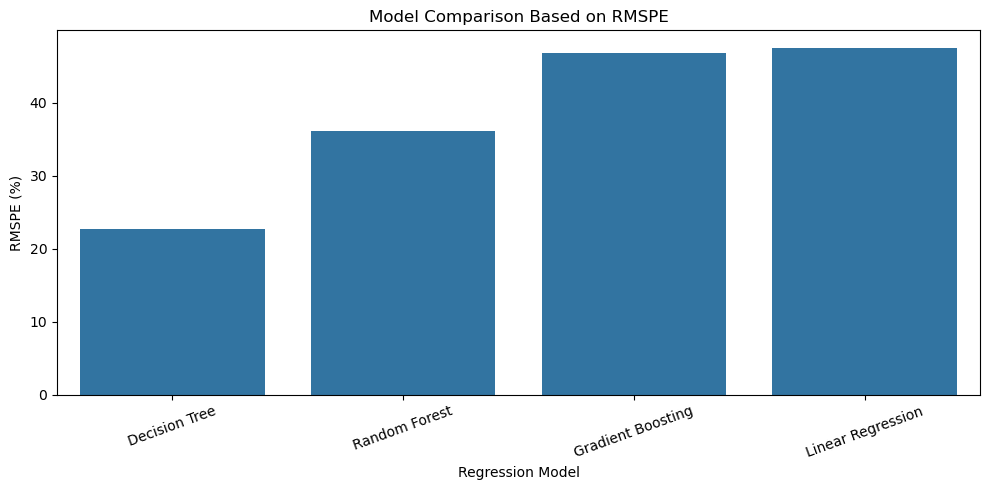

In [49]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSPE"
)

plt.title("Model Comparison Based on RMSPE")
plt.xlabel("Regression Model")
plt.ylabel("RMSPE (%)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [50]:
valid_open_mask = (
    train_df.loc[valid_mask, "Open"].values == 1
)

X_valid_open = X_valid.loc[valid_open_mask]
y_valid_open = y_valid.loc[valid_open_mask]

open_results = []

for name, model in trained_models.items():

    pred = np.maximum(
        model.predict(X_valid_open), 0
    )

    open_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_valid_open, pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_valid_open, pred)
        ),
        "R2": r2_score(y_valid_open, pred),
        "RMSPE": calculate_rmspe(y_valid_open, pred)
    })

open_results_df = pd.DataFrame(open_results)

display(
    open_results_df.sort_values("RMSPE").round(3)
)

,Model,MAE,RMSE,R2,RMSPE
1,Decision Tree,1063.160,1566.900,0.735,22.699
2,Random Forest,1602.424,2218.551,0.469,36.163
3,Gradient Boosting,1932.091,2731.222,0.195,46.744
0,Linear Regression,1908.019,2611.200,0.264,47.527


#### Insight
+ All four models are compared for open stores only.
+ Decision Tree remains the best-performing model, with an R² of 0.735. Its MAE and RMSE increase compared with the all-store evaluation.
+ Random Forest also experiences a decline in performance.
+ Gradient Boosting and Linear Regression show considerably weaker predictive performance.

In [51]:
best_model_name = (
    results_df.iloc[0]["Model"]
)

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Decision Tree


#### Overall Observations
+ The performance of four regression algorithms was evaluated under two scenarios: all stores (open and closed) and only open stores.
+ For the all-store evaluation, Decision Tree achieved the best performance, with an MAE of 917.94, RMSE of 1455.96, and R² score of 0.846. When evaluated exclusively on open stores, it maintained its position as the best-performing model, achieving an MAE of 1063.16, RMSE of 1566.90, and R² score of 0.735.
+ All models demonstrated lower prediction accuracy when evaluated only on open stores. This indicates that including closed-store records, which generally have zero sales, makes the overall prediction task easier. Predicting sales for open stores is more challenging because it involves capturing variations in customer demand, promotional activities, seasonal trends, and store-specific characteristics.
+ Decision Tree consistently outperformed the other algorithms in both evaluation scenarios. Therefore, it is selected as the leading candidate for further hyperparameter tuning and final sales prediction.

### Actual vs Predicted Sales

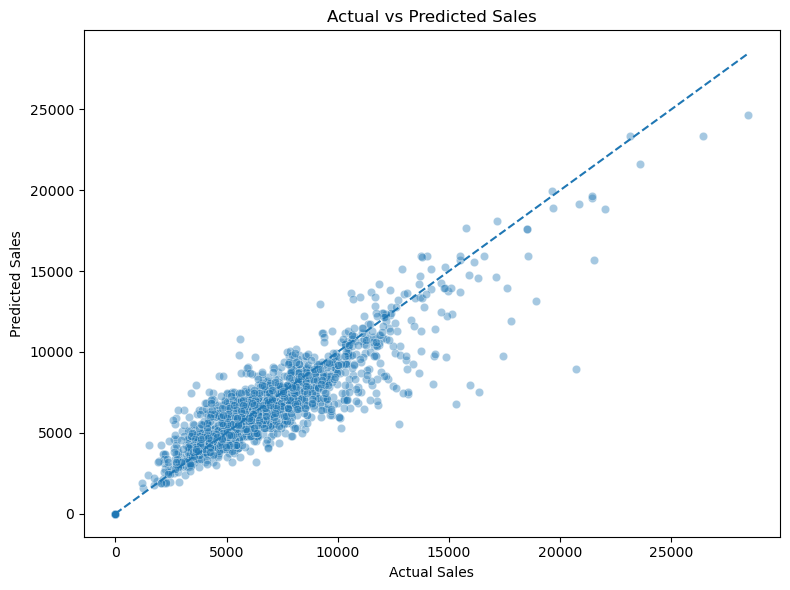

In [52]:
valid_predictions = np.maximum(
    best_model.predict(X_valid), 0
)

comparison_df = pd.DataFrame({
    "Actual_Sales": y_valid.values,
    "Predicted_Sales": valid_predictions
})

sample_comparison = comparison_df.sample(
    n=min(2000, len(comparison_df)),
    random_state=42
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=sample_comparison,
    x="Actual_Sales",
    y="Predicted_Sales",
    alpha=0.4
)

max_value = max(
    sample_comparison["Actual_Sales"].max(),
    sample_comparison["Predicted_Sales"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.tight_layout()
plt.show()

#### Insight 
1. Strong positive relationship: The points generally follow an upward trend, indicating that predicted sales increase as actual sales increase. This suggests that the model has learned the general relationship between input features and sales.

2. Good prediction for moderate sales: Most points are concentrated around the diagonal reference line, particularly when actual sales are approximately 3,000–10,000. This indicates comparatively good prediction performance in this range.

3. Underprediction for high sales: Several points representing higher actual sales (above approximately 15,000) fall below the diagonal line. This means the model predicts lower sales than the actual values for some high-performing stores.

4. Prediction errors increase at higher sales values: The scatter becomes wider as actual sales increase. This suggests that the model has difficulty accurately predicting sales for stores with exceptionally high demand.

5. Some overpredictions: A few points lie above the diagonal line, indicating that predicted sales are higher than actual sales for certain observations.

6. Overall model performance: Despite some deviations, the majority of observations remain reasonably close to the reference line, supporting the Decision Tree model's validation performance.

### Loss Function

+ Mean Absolute Error (MAE) is selected as the primary interpretable evaluation metric because it measures the average absolute difference between actual and predicted sales in the same units as the target variable. RMSE is also considered to give greater weight to large prediction errors, while RMSPE provides a relative measure of forecasting performance across stores with different sales volumes. Therefore, model selection considers multiple evaluation metrics rather than relying on a single score.

## Post Prediction Analysis

In [53]:
# Predictions from the trained Decision Tree pipeline

y_train_pred = best_model.predict(X_train)
y_pred = best_model.predict(X_valid)

# Calculate residuals
residuals = np.array(y_valid) - np.array(y_pred)

### Residual Distribution

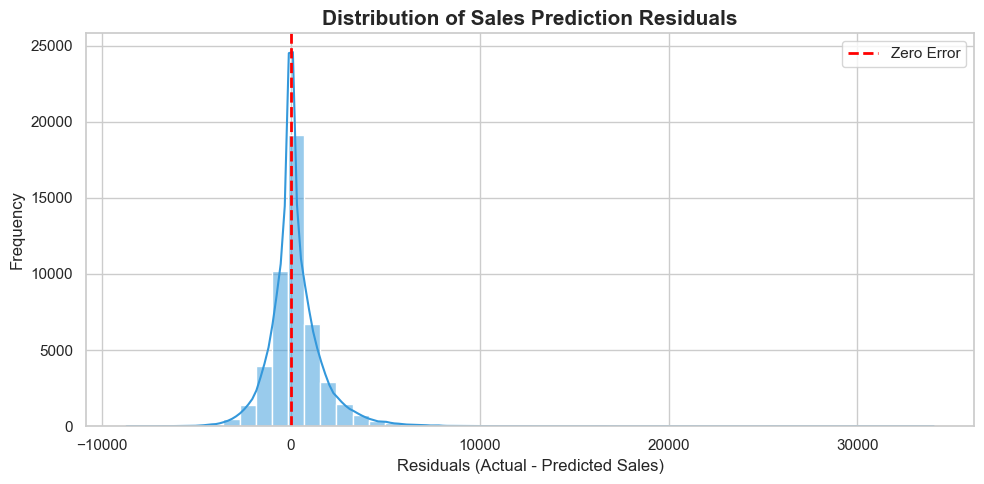

In [54]:
sns.set_theme(style="whitegrid", palette="deep")

plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=50,
    kde=True,
    color="#3498db"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.title("Distribution of Sales Prediction Residuals",
          fontsize=15, fontweight="bold")

plt.xlabel("Residuals (Actual - Predicted Sales)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

#### Insight
+ Most residuals are concentrated around zero, indicating that many predictions have relatively small errors.
+ The distribution has a noticeable peak near zero, suggesting that the model makes reasonably accurate predictions for a large number of observations.
+ The distribution is positively skewed, with a longer tail towards positive residual values.
+ Some residuals extend beyond 10,000 and even above 30,000, indicating substantial underprediction for a few observations.
+ The distribution is not perfectly symmetrical around zero, suggesting that prediction errors are not entirely balanced. Overall, the model performs reasonably well for most observations but struggles with some high-sales cases.

### Residual vs Predicted Sales

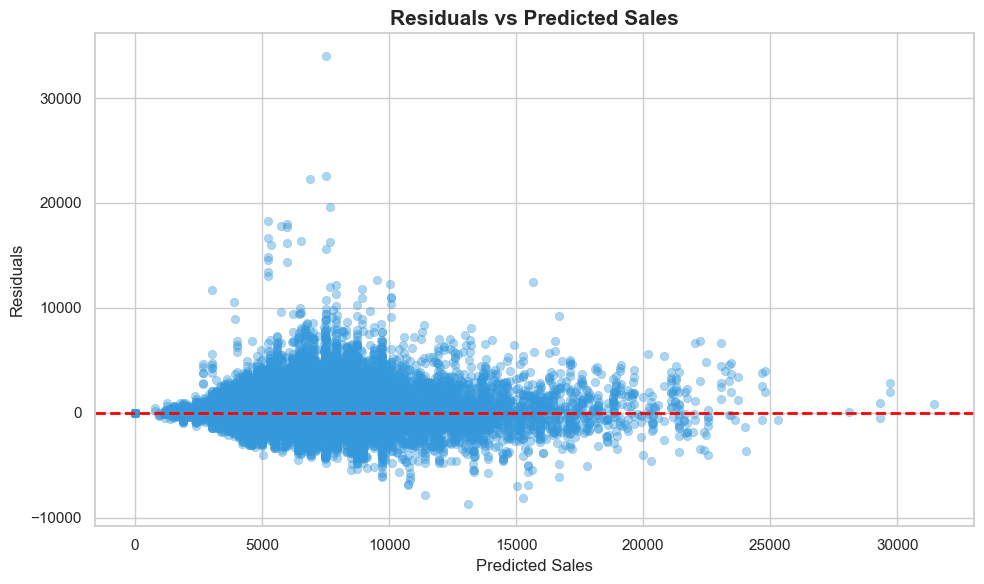

In [55]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=y_pred,
    y=residuals,
    alpha=0.4,
    color="#3498db",
    edgecolor=None
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Residuals vs Predicted Sales",
          fontsize=15, fontweight="bold")

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")

plt.tight_layout()
plt.show()

#### Insight
+ Most residuals are distributed around the zero reference line, indicating that the model does not consistently overpredict or underpredict every observation.
+ The spread of residuals varies across predicted sales values, suggesting non-constant error variance (heteroscedasticity). A wider spread is visible for predicted sales between approximately 4,000 and 10,000.
+ Several large positive residuals indicate observations where the model significantly underestimates sales.
+ A few negative residuals represent cases where predicted sales exceed actual sales.
+ Some extreme residuals suggest that the model may not capture unusual sales patterns effectively.

### Residual vs Actual Sales

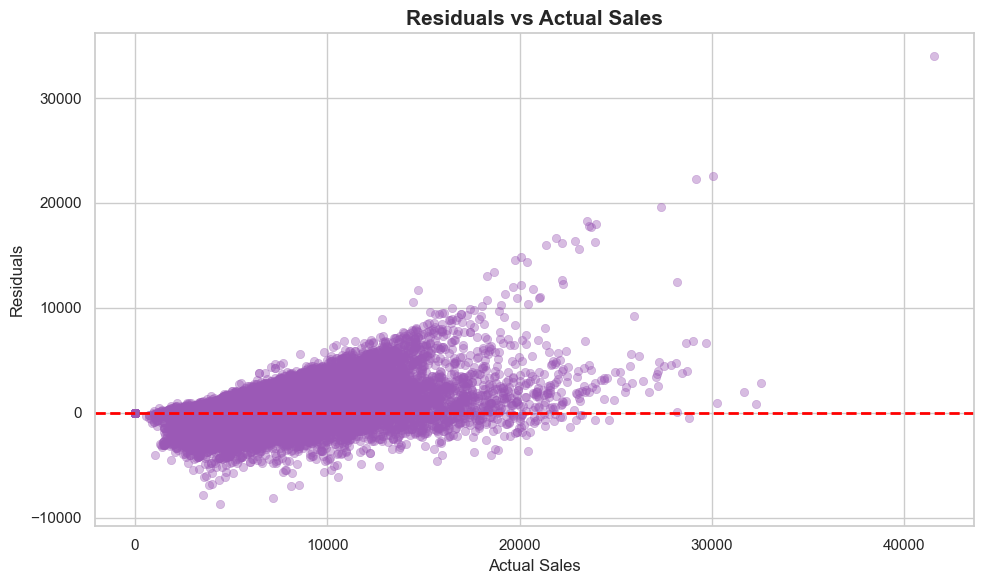

In [56]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=y_valid,
    y=residuals,
    alpha=0.4,
    color="#9b59b6",
    edgecolor=None
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Residuals vs Actual Sales",
          fontsize=15, fontweight="bold")

plt.xlabel("Actual Sales")
plt.ylabel("Residuals")

plt.tight_layout()
plt.show()


#### Insight
+ Residuals are relatively concentrated around zero for lower sales values. As actual sales increase, the spread of residuals becomes wider.
+ Several observations with actual sales above 15,000 have large positive residuals, indicating that the model underestimates sales for some high-performing stores.
+ The increasing spread suggests that the model's prediction errors are larger and less consistent for high-sales observations. A few observations show substantial negative residuals, indicating overprediction.

### Feature Importance

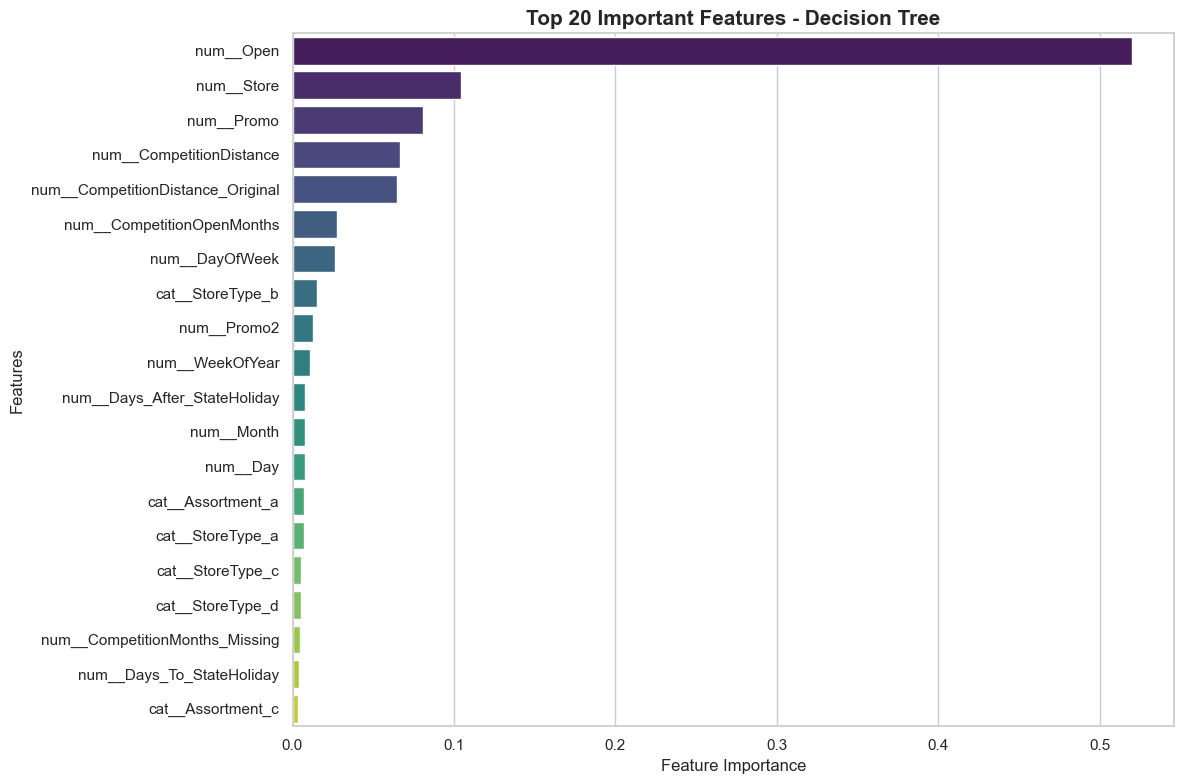

In [57]:
preprocessor_fitted = best_model.named_steps["preprocessor"]
decision_tree = best_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Extract feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": decision_tree.feature_importances_
})

# Sort and select top 20 features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(20)

# Plot
plt.figure(figsize=(12, 8))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 20 Important Features - Decision Tree",
          fontsize=15, fontweight="bold")

plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

#### Insight
+ Open is the most influential feature, accounting for approximately 52% of the model's total feature importance. This is expected because closed stores generally record zero sales.
+ Store is the second most important feature, indicating that sales patterns differ considerably between individual stores.
+ Promo has substantial importance, suggesting that promotional activities help explain sales variations.
+ Competition-related features contribute to the model's predictions, indicating that competitor proximity and opening duration provide useful information.
+ Day of the week, week of the year and month-related features contribute to capturing weekly and seasonal sales patterns.
+ Holiday-distance features have comparatively low importance in this fitted model.

Overall, the model relies heavily on store operating status and store-specific characteristics. However, feature importance represents the model's predictive usage of variables and does not establish a causal relationship with sales.

### Compare Training and Validation Performance

In [58]:
performance = pd.DataFrame({
    "Dataset": ["Training", "Validation"],

    "MAE": [
        mean_absolute_error(y_train, y_train_pred),
        mean_absolute_error(y_valid, y_pred)
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(y_train, y_train_pred)),
        np.sqrt(mean_squared_error(y_valid, y_pred))
    ],

    "R2": [
        r2_score(y_train, y_train_pred),
        r2_score(y_valid, y_pred)
    ]
})

display(performance.round(3))

,Dataset,MAE,RMSE,R2
0,Training,808.005,1288.001,0.888
1,Validation,917.938,1455.958,0.846


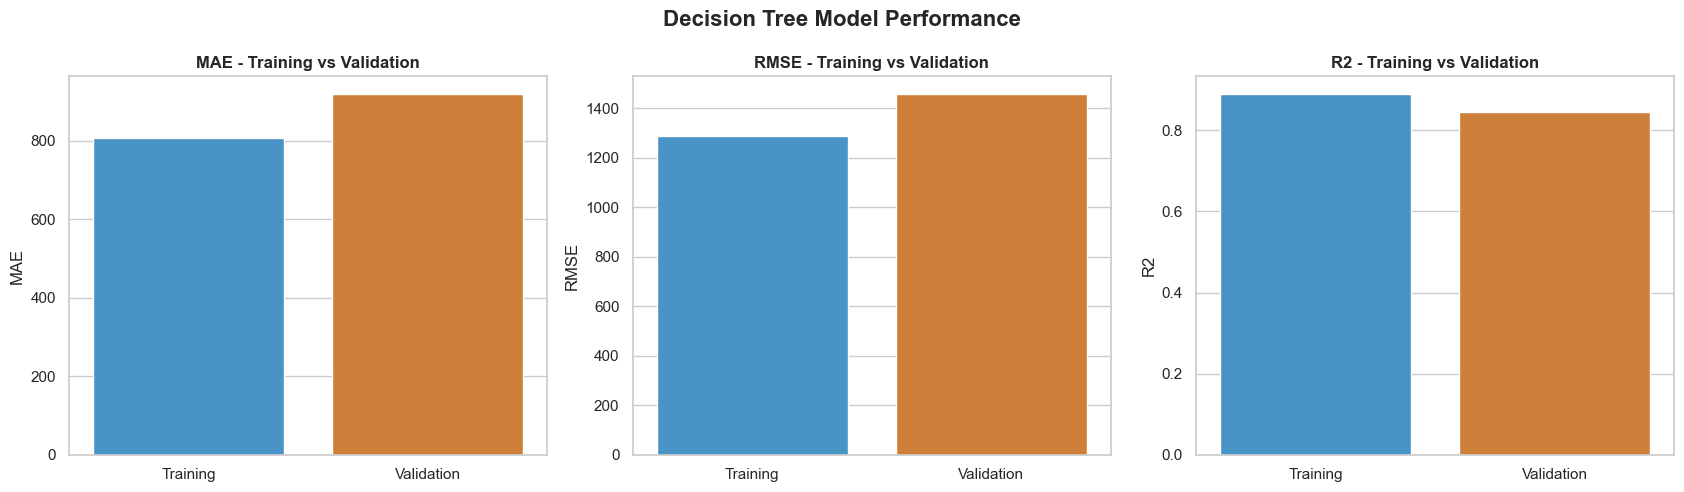

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = ["MAE", "RMSE", "R2"]
colors = ["#3498db", "#e67e22"]

for ax, metric in zip(axes, metrics):

    sns.barplot(
        data=performance,
        x="Dataset",
        y=metric,
        hue="Dataset",
        palette=colors,
        legend=False,
        ax=ax
    )

    ax.set_title(
        f"{metric} - Training vs Validation",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("")
    ax.set_ylabel(metric)

plt.suptitle(
    "Decision Tree Model Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Insight
1. Good predictive performance: The training R² is 0.888, while validation R² is 0.846. This indicates that the model explains approximately 84.6% of the variation in unseen validation sales data.

2. Small generalization gap: The difference between training and validation R² is only 0.042 (4.2 percentage points). This suggests that the model generalizes reasonably well to unseen data.

3. Slight increase in prediction errors: Validation MAE increases from 808.005 to 917.938. This is expected because the model is evaluated on data it has not seen during training.

4. No strong indication of overfitting: Although training performance is better, the difference between the two datasets is relatively small. The model does not show severe overfitting based on these metrics.

5. Consistent performance: Both MAE and RMSE remain reasonably close between training and validation, suggesting that the model maintains relatively stable prediction accuracy.

Overall, the model demonstrates good predictive performance with no strong indication of severe overfitting. Therefore, the Decision Tree Regressor is a promising candidate for further hyperparameter tuning and final sales prediction.

## Final Model Training and Serialization

In [60]:
from sklearn.base import clone

final_model = clone(best_model)

final_model.fit(X, y)

print("Final model trained successfully!")

Final model trained successfully!


In [61]:
timestamp = datetime.now().strftime(
    "%d-%m-%Y-%H-%M-%S"
)

model_filename = f"rossmann_sales_model_{timestamp}.pkl"

model_path = os.path.join(
    MODEL_DIR,
    model_filename
)

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Saved Path:", model_path)

Model saved successfully!
Saved Path: C:\Users\ijish\Desktop\Rossmann Sales Forecasting Project\models\rossmann_sales_model_12-11-2026-22-49-38.pkl


In [62]:
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")

Model loaded successfully!


### Predict Sales on Test Dataset

In [63]:
test_predictions = loaded_model.predict(X_test)

# Sales cannot be negative
test_predictions = np.maximum(test_predictions, 0)

# Set sales to zero for stores known to be closed
closed_mask = test_df["Open"].eq(0).values
test_predictions[closed_mask] = 0

print("Test predictions generated!")

Test predictions generated!


In [64]:
submission = pd.DataFrame({
    "Id": test_df["Id"],
    "Sales": test_predictions
})

submission.to_csv(
    os.path.join(OUTPUT_DIR, "rossmann_sales_predictions.csv"),
    index=False
)

display(submission.head())

,Id,Sales
0,1,4736.535836
1,2,7911.190476
2,3,8184.710227
3,4,8367.165320
4,5,7907.424242


## Customers Prediction Model

In addition to predicting daily store sales, this project aims to predict the number of customers visiting each store.

A separate machine learning model is developed for customer prediction using store characteristics, promotional activities, holidays, competition-related information, and date-based features.

The Customers model is trained independently from the Sales model to avoid target leakage and provide separate predictions for both business requirements.

### Customer Target

In [65]:
# Separate Customers target using the existing chronological split

y_customers = train_df["Customers"].copy()

y_customers_train = y_customers.loc[train_mask].copy()
y_customers_valid = y_customers.loc[valid_mask].copy()

print("Customers training shape:", y_customers_train.shape)
print("Customers validation shape:", y_customers_valid.shape)

print("X_train shape:", X_train.shape)
print("X_valid shape:", X_valid.shape)

Customers training shape: (969264,)
Customers validation shape: (47945,)
X_train shape: (969264, 28)
X_valid shape: (47945, 28)


In [66]:
print("Missing Customers:", y_customers.isna().sum())
print("Negative Customers:", (y_customers < 0).sum())

display(y_customers.describe())

Missing Customers: 0
Negative Customers: 0


count    1.017209e+06
mean     6.331459e+02
std      4.644117e+02
min      0.000000e+00
25%      4.050000e+02
50%      6.090000e+02
75%      8.370000e+02
max      7.388000e+03
Name: Customers, dtype: float64

### Train and Compare Customers Regression Models

In [67]:
from sklearn.base import clone

customer_models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=20,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        max_depth=15,
        min_samples_leaf=10,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=50,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=10,
        random_state=42
    )
}

trained_customer_models = {}
customer_results = []

for name, model in customer_models.items():

    print(f"\nTraining {name} for Customers...")

    customer_pipeline = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", model)
        ]
    )

    customer_pipeline.fit(
        X_train,
        y_customers_train
    )

    trained_customer_models[name] = customer_pipeline

    metrics = evaluate_model(
        customer_pipeline,
        X_valid,
        y_customers_valid
    )

    metrics["Model"] = name

    customer_results.append(metrics)

    print(f"{name} completed!")


Training Linear Regression for Customers...
Linear Regression completed!

Training Decision Tree for Customers...
Decision Tree completed!

Training Random Forest for Customers...
Random Forest completed!

Training Gradient Boosting for Customers...
Gradient Boosting completed!


### Compare Model Performance

In [68]:
customer_results_df = pd.DataFrame(customer_results)

customer_results_df = customer_results_df[
    ["Model", "MAE", "RMSE", "R2", "RMSPE"]
].sort_values("MAE")

display(customer_results_df.round(3))

,Model,MAE,RMSE,R2,RMSPE
1,Decision Tree,72.410,126.443,0.917,20.892
2,Random Forest,131.247,191.628,0.809,34.338
0,Linear Regression,188.815,285.257,0.577,48.861
3,Gradient Boosting,197.483,293.629,0.551,49.774


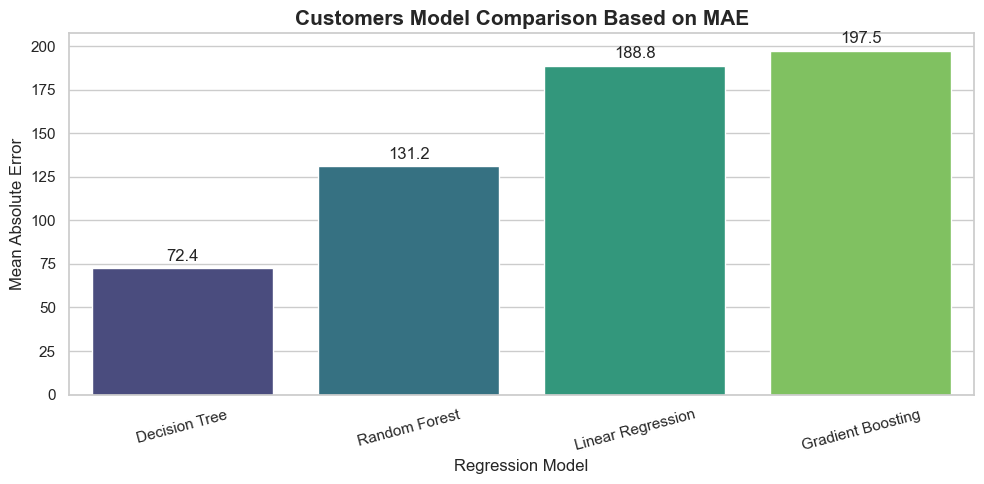

In [69]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=customer_results_df,
    x="Model",
    y="MAE",
    hue="Model",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

plt.title(
    "Customers Model Comparison Based on MAE",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Regression Model")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#### Insight

1. **Decision Tree performs best:** The Decision Tree Regressor achieves the lowest MAE of 72.41 and RMSE of 126.44, along with the highest R² score of 0.917. This indicates that it explains approximately 91.7% of the variation in customer numbers in the validation dataset.

2. **Random Forest ranks second:** Random Forest achieves an R² score of 0.809, with an MAE of 131.25. Although it performs reasonably well, its prediction errors are higher than those of the Decision Tree.

3. **Linear Regression shows comparatively weaker performance:** Its R² score of 0.577 indicates that a simple linear relationship is insufficient to capture all the patterns influencing customer visits.

4. **Gradient Boosting has the weakest performance:** It records an R² score of 0.551 and the highest MAE and RMSE among the evaluated models, suggesting that the current configuration does not capture customer patterns as effectively.

5. **Overall model selection:** The Decision Tree consistently provides the best results across the evaluation metrics. Therefore, it is selected as the best-performing candidate for the final Customers prediction model.

### Open Store Performance

In [70]:
valid_open_mask = (
    train_df.loc[valid_mask, "Open"].values == 1
)

X_valid_customers_open = X_valid.loc[valid_open_mask]

y_valid_customers_open = (
    y_customers_valid.loc[valid_open_mask]
)

customer_open_results = []

for name, model in trained_customer_models.items():

    pred = np.maximum(
        model.predict(X_valid_customers_open),
        0
    )

    customer_open_results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_valid_customers_open, pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_valid_customers_open, pred
            )
        ),
        "R2": r2_score(
            y_valid_customers_open, pred
        )
    })

customer_open_results_df = pd.DataFrame(
    customer_open_results
)

display(
    customer_open_results_df.sort_values("MAE").round(3)
)

,Model,MAE,RMSE,R2
1,Decision Tree,83.865,136.078,0.876
2,Random Forest,151.519,206.155,0.715
0,Linear Regression,212.800,305.922,0.372
3,Gradient Boosting,214.254,313.826,0.339


#### Insight

1. **Decision Tree remains the best model:** Even when evaluated exclusively on open stores, Decision Tree achieves the lowest MAE of 83.87 and RMSE of 136.08, with an R² score of 0.876.

2. **Performance decreases for open stores:** The Decision Tree's MAE increases from 72.41 to 83.87, while its R² decreases from 0.917 to 0.876. This indicates that predicting customer visits for operating stores is more challenging than predicting across all stores.

3. **Random Forest maintains second position:** It achieves an R² score of 0.715, but its errors are higher than those of the Decision Tree.

4. **Linear Regression and Gradient Boosting perform less effectively:** Both models show lower R² scores and higher prediction errors, indicating comparatively weaker performance for open-store customer prediction.

5. **Importance of open-store evaluation:** Including closed stores, which generally have zero customers, can make the overall prediction task easier. Evaluating open stores separately provides a more realistic assessment of the model's ability to predict actual customer demand.

Overall, Decision Tree maintains the best performance in both evaluation scenarios and remains the preferred model for Customers prediction.

### Best Customer Model

In [71]:
customer_best_model_name = (
    customer_results_df.iloc[0]["Model"]
)

best_customer_model = trained_customer_models[
    customer_best_model_name
]

print("Best Customers Model:", customer_best_model_name)

Best Customers Model: Decision Tree


#### Insight

Based on the validation results, the Decision Tree Regressor is selected as the best Customers prediction model. It demonstrates the lowest prediction errors and highest R² score among the four evaluated algorithms. The selected model is then retrained using the complete training dataset to utilize all available observations before generating predictions for the test dataset.

### Train the Final Customers Model on all Training Data

In [72]:
from sklearn.base import clone

final_customers_model = clone(best_customer_model)

final_customers_model.fit(
    X,
    y_customers
)

print("Final Customers model trained successfully!")

Final Customers model trained successfully!


### Save the Customer Model

In [73]:
customer_timestamp = datetime.now().strftime(
    "%d-%m-%Y-%H-%M-%S"
)

customer_model_filename = (
    f"rossmann_customers_model_{customer_timestamp}.pkl"
)

customer_model_path = os.path.join(
    MODEL_DIR,
    customer_model_filename
)

joblib.dump(
    final_customers_model,
    customer_model_path
)

print("Customers model saved successfully!")
print("Saved path:", customer_model_path)

Customers model saved successfully!
Saved path: C:\Users\ijish\Desktop\Rossmann Sales Forecasting Project\models\rossmann_customers_model_12-11-2026-22-53-37.pkl


In [74]:
loaded_sales_model = joblib.load(model_path)

loaded_customers_model = joblib.load(
    customer_model_path
)

print("Sales model loaded successfully!")
print("Customers model loaded successfully!")

Sales model loaded successfully!
Customers model loaded successfully!


In [75]:
sales_check = loaded_sales_model.predict(
    X_test.head(5)
)

customers_check = loaded_customers_model.predict(
    X_test.head(5)
)

print("Sales predictions:", sales_check)
print("Customers predictions:", customers_check)

Sales predictions: [4736.53583618 7911.19047619 8184.71022727 8367.16531962 7907.42424242]
Customers predictions: [ 533.51515152  797.1595092  1070.37096774  791.1452381   646.08333333]


#### Insight

+ The Sales and Customers prediction results have been combined into a single store-level prediction dataset. This provides both expected sales revenue and estimated customer visits for each store and date.

+ The combined output can help analyze the relationship between customer demand and expected sales, compare store-level performance, and support business planning. The predictions are generated independently using the selected Sales and Customers models.

### Predict Customer for Test Dataset

In [76]:
# Predict Customers
customers_test_predictions = (
    loaded_customers_model.predict(X_test)
)

# Customers cannot be negative
customers_test_predictions = np.maximum(
    customers_test_predictions,
    0
)

# Set Customers to zero for known closed stores
closed_mask = test_df["Open"].eq(0).values

customers_test_predictions[closed_mask] = 0

print("Customers predictions generated!")

Customers predictions generated!


### Save Customer Predictions

In [77]:
customers_submission = pd.DataFrame({
    "Id": test_df["Id"],
    "Customers": np.round(
        customers_test_predictions
    ).astype(int)
})

customers_submission.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "rossmann_customers_predictions.csv"
    ),
    index=False
)

display(customers_submission.head())

,Id,Customers
0,1,534
1,2,797
2,3,1070
3,4,791
4,5,646


### Combine Store-Level Predictions 

In [78]:
store_predictions = pd.DataFrame({
    "Id": test_df["Id"],
    "Store": test_df["Store"],
    "Date": test_df["Date"],
    "Predicted_Sales": np.maximum(
        loaded_sales_model.predict(X_test), 0
    ),
    "Predicted_Customers": customers_test_predictions
})

store_predictions.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "rossmann_store_level_predictions.csv"
    ),
    index=False
)

display(store_predictions.head(10))

,Id,Store,Date,Predicted_Sales,Predicted_Customers
0,1,1,2015-09-17,4736.535836,533.515152
1,2,3,2015-09-17,7911.190476,797.159509
2,3,7,2015-09-17,8184.710227,1070.370968
3,4,8,2015-09-17,8367.165320,791.145238
4,5,9,2015-09-17,7907.424242,646.083333
5,6,10,2015-09-17,6872.031259,612.522727
6,7,11,2015-09-17,8143.274510,1085.365385
7,8,12,2015-09-17,8143.274510,939.966667
8,9,13,2015-09-17,5418.500000,405.416667
9,10,14,2015-09-17,5868.006154,676.981516


### Save Metadata for Deployment

In [80]:
import json
metadata = {
    "sales_model_file": os.path.basename(model_path),
    "customers_model_file": os.path.basename(customer_model_path),
    "features": X.columns.tolist(),
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "sales_best_model": best_model_name,
    "customers_best_model": customer_best_model_name,
    "sales_target": "Sales",
    "customers_target": "Customers"
}

metadata_path = os.path.join(
    MODEL_DIR,
    "model_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Model metadata saved!")

Model metadata saved!


## Export Models and Results for MLflow

The trained candidate models and their evaluation results are exported
so that they can be accessed from a separate MLflow tracking notebook
without retraining the models.

In [ ]:
# Create folder for MLflow input files
MLFLOW_INPUT_DIR = os.path.join(
    MODEL_DIR,
    "mlflow_inputs"
)

os.makedirs(MLFLOW_INPUT_DIR, exist_ok=True)

# Export candidate Sales models
joblib.dump(
    trained_models,
    os.path.join(
        MLFLOW_INPUT_DIR,
        "sales_candidate_models.pkl"
    )
)

# Export candidate Customers models
joblib.dump(
    trained_customer_models,
    os.path.join(
        MLFLOW_INPUT_DIR,
        "customers_candidate_models.pkl"
    )
)

# Export Sales evaluation results
results_df.to_csv(
    os.path.join(
        MLFLOW_INPUT_DIR,
        "sales_validation_results.csv"
    ),
    index=False
)

open_results_df.to_csv(
    os.path.join(
        MLFLOW_INPUT_DIR,
        "sales_open_store_results.csv"
    ),
    index=False
)

# Export Customers evaluation results
customer_results_df.to_csv(
    os.path.join(
        MLFLOW_INPUT_DIR,
        "customers_validation_results.csv"
    ),
    index=False
)

customer_open_results_df.to_csv(
    os.path.join(
        MLFLOW_INPUT_DIR,
        "customers_open_store_results.csv"
    ),
    index=False
)

print("All MLflow input files exported successfully!")

In [82]:
split_info = {
    "training_rows": int(len(X_train)),
    "validation_rows": int(len(X_valid)),
    "feature_count": int(X.shape[1])
}

with open(
    os.path.join(MLFLOW_INPUT_DIR, "split_info.json"),
    "w"
) as f:
    json.dump(split_info, f, indent=4)

print("Split information exported!")


Split information exported!


## Final Observations and Conclusion

### Overall Observations

The Rossmann Store Sales Forecasting project involved data preprocessing, exploratory data analysis, feature engineering, machine learning model development, evaluation, and test prediction generation.

The following key observations were obtained:

1. **Sales Model Performance:** Among the four evaluated regression algorithms, Decision Tree achieved the best validation performance, with an MAE of 917.94, RMSE of 1455.96, and R² score of 0.846.

2. **Customers Model Performance:** Decision Tree also performed best for Customers prediction, achieving an MAE of 72.41, RMSE of 126.44, and R² score of 0.917 on the validation dataset.

3. **Open-Store Evaluation:** Both Sales and Customers models maintained Decision Tree as the best-performing algorithm when evaluated exclusively on open stores. However, prediction errors increased because forecasting actual demand for operating stores is more challenging than predicting across both open and closed stores.

4. **Feature Importance:** For Sales prediction, store operating status, store identification, promotional activities, and competition-related features were among the most influential variables.

5. **Model Generalization:** The Sales Decision Tree achieved an R² score of 0.888 on training data and 0.846 on validation data, indicating a relatively small performance gap. The Customers Decision Tree also demonstrated strong validation performance.

6. **Separate Prediction Models:** Independent machine learning pipelines were developed for Sales and Customers prediction. This allows both business targets to be predicted separately using the same input features.

7. **Final Predictions:** The selected models were retrained using the complete training dataset, saved as timestamped model files, and used to generate predictions for the test dataset.

8. **Combined Output:** Sales and Customers predictions were combined into a single store-level dataset containing store identifiers, dates, predicted sales, and predicted customer numbers.

### Conclusion

+ This project demonstrates how machine learning techniques can be used to forecast daily sales and customer visits across multiple retail stores.

+ The Decision Tree Regressor emerged as the best-performing model for both Sales and Customers prediction among the four algorithms evaluated. The results highlight the importance of store characteristics, operating status, promotional activities, and calendar-related information in understanding retail demand.

+ The final models were serialized and used to generate predictions for the test dataset. The combined prediction output provides useful information for analyzing expected store performance and supporting business planning.

+ Although the models demonstrate promising validation performance, further improvements through hyperparameter tuning, additional feature engineering, and prediction uncertainty analysis may help improve forecasting reliability.

Overall, this project establishes a machine learning-based forecasting workflow that can support sales planning, customer demand estimation, and data-driven decision-making for retail operations.

In [1]:
import sys

print(sys.executable)

C:\Users\ijish\anaconda3\python.exe
